# MADT 7202 Mid-Term Applied Case — Notebook (evidence that the one-pager is real)
**Question:** *Which long-haul markets should TAT (ททท.) protect first when the Gulf hubs (Dubai, Doha, Abu Dhabi) close?*

Notebook นี้ทำซ้ำ (reproduce) ตัวเลขทุกตัวในเอกสาร 1 หน้า ตั้งแต่ข้อมูลดิบระดับ "คู่เมือง × สัปดาห์" ไปจนถึงตาราง Section 7 ท้ายสุดมีเซลล์ตรวจว่าตัวเลขที่คำนวณได้ **ตรงกับตัวเลขในเอกสาร** หรือไม่

| ขั้น | ทำอะไร | ผลลัพธ์ที่ใช้ใน One-pager |
|---|---|---|
| 1 | อัปโหลดไฟล์ข้อมูล | – |
| 2 | โหลด + ทำความสะอาด (ตัด `***Unspecified***`) | Section 3 (data, 1.96M rows) |
| 3 | **Prune** (ตัดเส้นทาง < 3 เที่ยว/สัปดาห์) + สร้างกราฟ | Section 4 (1,196→978 nodes, 22,401→15,533 edges) |
| 4 | วิเคราะห์ **Exposure E** (ตัวอย่าง UK→Thailand) | Section 4 |
| 5 | E ของ 20 ตลาด × 6 ปลายทาง | Section 5–6 |
| 6 | ทดสอบ (validate) กับจำนวนนักท่องเที่ยว Mar–Apr 2026: Spearman ρ, placebo, leave-one-hub-out | Section 6 |
| 7 | Robustness 48 specifications | Section 6 |
| 8 | Vietnam / Japan (difference-in-differences) | Section 6 |
| 9 | Capacity lost ถ้าปิด 3 ฮับ + เส้นทาง Gulf→ปลายทาง | Section 5–6 (figure) |
| 10 | Trigger rule (Europe→Gulf ต่ำกว่าปีก่อน ≥10% สองสัปดาห์) | Section 7 |
| 11 | ตรวจความถูกต้องด้วย UK CAA | Section 3 |
| 12 | ตาราง Exposed + การแบ่งงบ | Section 7 |
| 13 | วาดรูปเครือข่าย | Section 5 |
| 14 | **สรุป + แปลผล** และเซลล์ตรวจตัวเลข | Section 6–8 |
| 15 | บันทึกผลเป็น Excel | – |

**วิธีใช้ใน Google Colab:** เปิดไฟล์นี้ใน Colab → *Runtime ▸ Run all* (หรือกดรันทีละเซลล์) → เมื่อถึงขั้น 1 ให้เลือกไฟล์ทั้งหมดในโฟลเดอร์ `colab_inputs/` อัปโหลดพร้อมกัน

## Step 0 — Setup (ติดตั้ง/นำเข้าไลบรารี)
Colab มี pandas, numpy, scipy, networkx, matplotlib, statsmodels ให้อยู่แล้ว ไม่ต้องติดตั้งเพิ่ม

In [1]:
import json, os, collections, warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)

RESULTS = {}          # เก็บตารางผลลัพธ์ไว้เขียนลง Excel ตอนท้าย (Step 15)
CHECKS  = []          # เก็บ (ชื่อ, ค่าที่คำนวณ, ค่าใน one-pager, tolerance) ไว้ตรวจตอนท้าย (Step 14)
def check(name, got, expected, tol): CHECKS.append((name, got, expected, tol))
print('ready')

ready


## Step 1 — Upload files (อัปโหลดไฟล์)
เมื่อรันเซลล์ด้านล่างใน Colab จะมีปุ่ม **Choose files** ให้เลือกไฟล์ **ทั้ง 11 ไฟล์** ในโฟลเดอร์ `colab_inputs/` พร้อมกัน

| ไฟล์ | เนื้อหา | ที่มา |
|---|---|---|
| `flights_city_pair_weekly_2026.csv.gz` | เที่ยวบินตามตารางบินรายสัปดาห์ ต้นทาง→ปลายทาง (ระดับเมือง) ปี 2026 รวมทุกสายการบิน | ฐานข้อมูลตารางบินของสถาบัน (export 24 ก.ย. 2569) |
| `flights_city_pair_weekly_2025.csv.gz` | เหมือนกัน แต่ปี 2025 (ใช้เป็น placebo และตัวตั้งต้น YoY ของ trigger) | เหมือนกัน |
| `citymap.json` | เมือง → รหัสประเทศ และ ประเทศ → ทวีป | ตารางจับคู่ที่เราสร้าง |
| `tourism_arrivals_monthly_clean.csv` | นักท่องเที่ยวต่างชาติเข้าไทยรายเดือนตามสัญชาติ | กระทรวงการท่องเที่ยวและกีฬา (MOTS) |
| `market_value_priority_2568.csv` | รายรับ (receipts) ปี 2025 ต่อสัญชาติ, บาท/ทริป | MOTS |
| `vn_arrivals_2025_parsed.csv`, `vn_arrivals_2026_parsed.csv` | นักท่องเที่ยวเข้าเวียดนามรายเดือนตามสัญชาติ | สถิติเวียดนาม |
| `japan_jnto_arrivals_by_nationality_monthly_2019_2026.csv` | นักท่องเที่ยวเข้าญี่ปุ่นรายเดือน | JNTO |
| `corridor_Weekly_city_2025.csv`, `corridor_Weekly_city_2026.csv` | จำนวนเที่ยวบินรายสัปดาห์แยก corridor (เช่น Europe→Gulf3) | สรุปจากตารางบิน |
| `corridor_flight_citypair_weekly_asof_2026-10-02_svc-2026-09_2027-01.csv` | ตารางบินล่วงหน้า (as of 2 ต.ค. 2569) ก.ย. 2026–ม.ค. 2027 | เหมือนกัน |

> ข้อมูลตารางบินเป็นข้อมูลที่ได้ลิขสิทธิ์เพื่อการศึกษา — ไฟล์ที่แนบเป็น **ข้อมูลรวม (aggregate) ระดับคู่เมือง×สัปดาห์** ไม่มีข้อมูลส่วนบุคคล

In [2]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    uploaded = files.upload()          # เลือกไฟล์ทั้งหมดในโฟลเดอร์ colab_inputs/
    DATA = '.'
else:                                  # รันบนเครื่องตัวเอง: วางไฟล์ไว้ใน ./colab_inputs
    DATA = 'colab_inputs'

NEED = ['flights_city_pair_weekly_2026.csv.gz','flights_city_pair_weekly_2025.csv.gz','citymap.json',
        'tourism_arrivals_monthly_clean.csv','market_value_priority_2568.csv','vn_arrivals_2025_parsed.csv',
        'vn_arrivals_2026_parsed.csv','japan_jnto_arrivals_by_nationality_monthly_2019_2026.csv',
        'corridor_Weekly_city_2025.csv','corridor_Weekly_city_2026.csv',
        'corridor_flight_citypair_weekly_asof_2026-10-02_svc-2026-09_2027-01.csv']
missing = [f for f in NEED if not os.path.exists(f'{DATA}/{f}')]
print('ไฟล์ที่ยังไม่ครบ:', missing if missing else 'ไม่มี — ครบทุกไฟล์ ✔')
assert not missing, 'กรุณาอัปโหลดไฟล์ที่ขาดก่อนรันต่อ'

ไฟล์ที่ยังไม่ครบ: ไม่มี — ครบทุกไฟล์ ✔


## Step 2 — Load & clean (โหลดและทำความสะอาด)
แต่ละแถว = เที่ยวบินตามตาราง ของ **ต้นทาง → ปลายทาง** ในสัปดาห์หนึ่ง (รวมทุกสายการบิน)

การทำความสะอาด:
1. ตัดแถวที่ต้นทางหรือปลายทางเป็น `***Unspecified***` (ประมาณ 0.9% ของเที่ยวบิน — ระบุเมืองไม่ได้ จึงวางบนกราฟไม่ได้)
2. ปี 2025: เลื่อนวันที่ **+364 วัน** เพื่อให้สัปดาห์ตรงกับปฏิทิน 2026 (วันอังคารตรงกับวันอังคาร) ใช้เทียบ YoY แบบสัปดาห์ต่อสัปดาห์
3. อ่าน `citymap.json` เพื่อรู้ว่าเมืองไหนอยู่ประเทศอะไร

> **จำนวนแถว:** ไฟล์ต้นฉบับปี 2026 มี **1,964,747 แถวระดับสายการบิน** (สายการบิน 524 ราย + `***Unspecified***`) — ตัวเลข "1.96M rows, 524 airlines" ใน one-pager มาจากไฟล์นั้น ไฟล์ที่แนบใน Colab **รวมทุกสายการบินแล้ว** (ลิขสิทธิ์ให้เผยแพร่ได้เฉพาะ aggregate) จึงเหลือ 1,204,977 แถว (คู่เมือง × สัปดาห์) ผลรวมเที่ยวบินเท่าเดิม

In [3]:
UNSP = '***Unspecified***'
raw26 = pd.read_csv(f'{DATA}/flights_city_pair_weekly_2026.csv.gz', parse_dates=['week'])
raw25 = pd.read_csv(f'{DATA}/flights_city_pair_weekly_2025.csv.gz', parse_dates=['week'])

def clean(d):
    bad = (d.departure_city == UNSP) | (d.arrival_city == UNSP)
    print(f'  แถวทั้งหมด {len(d):,} | Unspecified {bad.sum():,} แถว = {d.loc[bad,"flights"].sum()/d.flights.sum():.2%} ของเที่ยวบิน')
    return d[~bad].copy()

print('2026:'); r26 = clean(raw26)
print('2025:'); r25 = clean(raw25)
r25['week'] = r25.week + pd.Timedelta(days=364)         # จัดสัปดาห์ให้ตรงปฏิทิน 2026
print('สัปดาห์ 2026:', r26.week.min().date(), '→', r26.week.max().date(), '| จำนวนสัปดาห์', r26.week.nunique())

cm = json.load(open(f'{DATA}/citymap.json'))
city_country = cm['city_country']                       # เมือง -> รหัสประเทศ 2 ตัว (เช่น 'Bangkok' -> 'TH')
country_continent = cm['country_continent']             # รหัสประเทศ -> ทวีป
cc = {}                                                  # รหัสประเทศ -> รายชื่อเมือง
for city, code in city_country.items(): cc.setdefault(code, []).append(city)
print('ประเทศที่มีเมืองในแผนที่:', len(cc), '| เมืองในไทย:', len(cc['TH']))

2026:
  แถวทั้งหมด 1,204,977 | Unspecified 10,317 แถว = 0.93% ของเที่ยวบิน
2025:


  แถวทั้งหมด 1,224,110 | Unspecified 6,382 แถว = 0.47% ของเที่ยวบิน
สัปดาห์ 2026: 2026-01-06 → 2026-12-29 | จำนวนสัปดาห์ 52
ประเทศที่มีเมืองในแผนที่: 203 | เมืองในไทย: 12


## Step 3 — Prune + Build graph (ตัดเส้นทางเล็ก แล้วสร้างกราฟ)
**นิยามกราฟ**
- **Node** = เมือง
- **Edge (มีทิศทาง)** = เส้นทางบินตรง (nonstop) ต้นทาง → ปลายทาง
- **Weight** = จำนวนเที่ยวบินเฉลี่ยต่อสัปดาห์ ในช่วง **6 ม.ค. – 17 ก.พ. 2026 (7 สัปดาห์ก่อนปิดฮับ)** — ช่วงนี้ยังไม่มีเหตุการณ์ จึงวัด "โครงสร้างที่พึ่งพิงอยู่ก่อนเกิดเหตุ"

**Prune (ตัดแต่ง):** ตัดเส้นทางที่ < **3 เที่ยว/สัปดาห์** ออกทุกปลายทางเท่ากัน (ตัด charter/เส้นทางเฉพาะกิจ) — ใน Step 7 เราทดสอบ cutoff 1/3/7/14 เพื่อดูว่าผลไม่ขึ้นกับตัวเลขนี้

**ไม่ได้เริ่มจากฮับ Gulf (not Gulf-seeded):** เราสร้างกราฟทั้งโลกก่อน แล้วค่อยวัดว่า Gulf อยู่ตรงไหน เพื่อไม่ให้ผลวนกลับมาที่สมมติฐาน

In [4]:
PRE = ('2026-01-06', '2026-02-17')        # หน้าต่างก่อนปิดฮับ (7 สัปดาห์)
CUT = 3                                    # เกณฑ์ prune (เที่ยว/สัปดาห์)

def build(r, window=PRE, cutoff=CUT):
    """คืน W (adjacency matrix น้ำหนัก = เที่ยว/สัปดาห์), ix (เมือง->index), e (edge list หลัง prune), nw, (nodes_ก่อน, pairs_ก่อน)"""
    d = r if window is None else r[(r.week >= window[0]) & (r.week <= window[1])]
    nw = d.week.nunique()
    e = d.groupby(['departure_city', 'arrival_city']).flights.sum().div(nw).rename('flights_wk').reset_index()
    before = (len(set(e.departure_city) | set(e.arrival_city)), len(e))
    e = e[e.flights_wk >= cutoff]                                    # <<< PRUNE
    cities = sorted(set(e.departure_city) | set(e.arrival_city))
    ix = {c: i for i, c in enumerate(cities)}
    W = np.zeros((len(cities), len(cities)))
    W[e.departure_city.map(ix).values, e.arrival_city.map(ix).values] = e.flights_wk.values
    return W, ix, e, nw, before

W, ix, e, nw, before = build(r26)
print(f'จำนวนสัปดาห์ในหน้าต่าง: {nw}')
print(f'ก่อน prune : {before[0]:,} nodes, {before[1]:,} edges')
print(f'หลัง prune : {len(ix):,} nodes, {len(e):,} edges   (เกณฑ์ ≥ {CUT} เที่ยว/สัปดาห์)')
allp = r26[(r26.week >= PRE[0]) & (r26.week <= PRE[1])].groupby(['departure_city','arrival_city']).flights.sum().div(nw)
print(f'เที่ยวบินที่ถูกตัดทิ้ง: {allp[allp<CUT].sum()/allp.sum():.1%} ของเที่ยวบินทั้งหมด (จำนวน edge ที่ตัด {(allp<CUT).sum():,})')
check('nodes หลัง prune', len(ix), 978, 0); check('edges หลัง prune', len(e), 15533, 0)
check('nodes ก่อน prune', before[0], 1196, 0); check('edges ก่อน prune', before[1], 22401, 0)

# ตารางเส้นทางทั้งหมดก่อน prune (ใส่ flag ว่าอยู่หลัง prune ไหม) เก็บลง Excel
edges_all = allp.rename('flights_wk').reset_index()
edges_all['kept_after_prune'] = edges_all.flights_wk >= CUT
RESULTS['edges_preclosure_all'] = edges_all.round(3).sort_values('flights_wk', ascending=False)

จำนวนสัปดาห์ในหน้าต่าง: 7
ก่อน prune : 1,196 nodes, 22,401 edges
หลัง prune : 978 nodes, 15,533 edges   (เกณฑ์ ≥ 3 เที่ยว/สัปดาห์)
เที่ยวบินที่ถูกตัดทิ้ง: 4.2% ของเที่ยวบินทั้งหมด (จำนวน edge ที่ตัด 6,868)


### 3.1 สร้างเป็นกราฟ NetworkX และดูลักษณะทั่วไป
ใช้เพื่อตรวจว่ากราฟ "หน้าตาเหมือนเครือข่ายสายการบินจริง" (ไม่กี่ฮับเชื่อมเมืองเล็กจำนวนมาก) — **ไม่จัดอันดับเมืองหรือฮับ** (ตามคำเตือนในโจทย์เรื่อง seed entity)

In [5]:
G = nx.from_pandas_edgelist(e, 'departure_city', 'arrival_city', edge_attr='flights_wk', create_using=nx.DiGraph)
print('nodes', G.number_of_nodes(), '| edges', G.number_of_edges(), '| density', round(nx.density(G), 4))
print('weakly connected components:', nx.number_weakly_connected_components(G),
      '| ขนาดก้อนใหญ่สุด', len(max(nx.weakly_connected_components(G), key=len)))
deg = pd.Series(dict(G.out_degree(weight='flights_wk'))).sort_values(ascending=False)
share_top = deg.head(int(len(deg) * 0.05)).sum() / deg.sum()
print(f'ลักษณะ hub-and-spoke: เมืองมัธยฐานมีเที่ยวบินขาออก {deg.median():.0f}/สัปดาห์; เมือง 5% บนสุดรับ {share_top:.0%} ของเที่ยวบินทั้งหมด')
print('(ไม่จัดอันดับเมือง/ฮับ — เพื่อไม่ให้ฮับ Gulf ที่เป็นหัวข้อของเราขึ้นมาเป็น "ผลลัพธ์" จากวิธีเก็บข้อมูล)')
gulf = ['Dubai', 'Doha', 'Abu Dhabi']
print('\nสามฮับ Gulf — เที่ยวบินเข้า/ออก ต่อสัปดาห์:')
print(pd.DataFrame({'in': [W[:, ix[h]].sum() for h in gulf], 'out': [W[ix[h], :].sum() for h in gulf]}, index=gulf).round(0))

nodes 978 | edges 15533 | density 0.0163
weakly connected components: 4 | ขนาดก้อนใหญ่สุด 971
ลักษณะ hub-and-spoke: เมืองมัธยฐานมีเที่ยวบินขาออก 38/สัปดาห์; เมือง 5% บนสุดรับ 51% ของเที่ยวบินทั้งหมด
(ไม่จัดอันดับเมือง/ฮับ — เพื่อไม่ให้ฮับ Gulf ที่เป็นหัวข้อของเราขึ้นมาเป็น "ผลลัพธ์" จากวิธีเก็บข้อมูล)

สามฮับ Gulf — เที่ยวบินเข้า/ออก ต่อสัปดาห์:
               in     out
Dubai      4905.0  5080.0
Doha       2783.0  2986.0
Abu Dhabi  1864.0  1992.0


## Step 4 — Exposure E (ตัวชี้วัดความพึ่งพิง Gulf)
สำหรับตลาดต้นทาง **R** (เช่น UK) ไปปลายทาง **D** (เช่น Thailand):

- **C0** = ความจุบินตรง R→D (เที่ยว/สัปดาห์)
- **Ch(h)** = ความจุเส้นทาง 2 ช่วง (R→h→D) ที่ผ่านฮับ *h*
  \[ Ch(h) = \frac{\text{in}(h)\times \text{out}(h)}{W_{out}(h)} \]
  โดย in(h) = เที่ยวบิน R→h, out(h) = เที่ยวบิน h→D, W_out(h) = เที่ยวบินขาออกทั้งหมดของ h (กระจายผู้โดยสารที่ต่อเครื่องตามสัดส่วนเที่ยวบินขาออกของฮับ — *proportional allocation*)
- **E(R,D)** = Σ Ch(h) เฉพาะฮับ Gulf {Dubai, Doha, Abu Dhabi} ÷ [C0 + Σ Ch(h) ทุกฮับ]

ความหมาย: ในความจุทั้งหมดที่ R ใช้ไป D (ทั้งบินตรงและต่อเครื่อง) มีสัดส่วนเท่าใดที่ต้อง **เปลี่ยนเครื่องในฮับ Gulf** (เป็น *routing proxy* ไม่ใช่พฤติกรรมของผู้โดยสาร)

ทางเลือก **min-leg**: Ch(h) = min(in(h), out(h)) — ใช้เป็น sensitivity

In [6]:
HUB = {'narrow': ['Dubai', 'Doha'],
       'main'  : ['Dubai', 'Doha', 'Abu Dhabi'],                                   # <<< ใช้ใน one-pager
       'wide'  : ['Dubai','Doha','Abu Dhabi','Sharjah','Muscat','Bahrain','Kuwait','Riyadh','Jeddah']}
GULF3 = HUB['main']

def exposure(W, ix, ocodes, dcodes, hubs=GULF3, alloc='prop'):
    """E(R->D). ocodes/dcodes = list ของรหัสประเทศ (ต้นทาง/ปลายทาง)"""
    ocs = [c for k in ocodes for c in cc.get(k, []) if c in ix]
    dcs = [c for k in dcodes for c in cc.get(k, []) if c in ix]
    if not ocs or not dcs: return None
    oi = [ix[c] for c in ocs]; di = [ix[c] for c in dcs]
    Wout = W.sum(1).copy(); Wout[Wout == 0] = np.inf             # เที่ยวบินขาออกรวมของแต่ละเมือง
    inflow  = W[oi, :].sum(0)                                      # in(h): R -> h
    outflow = W[:, di].sum(1)                                      # out(h): h -> D
    C0 = W[np.ix_(oi, di)].sum()                                   # บินตรง R -> D
    Ch = inflow * outflow / Wout if alloc == 'prop' else np.minimum(inflow, outflow)
    for c in ocs + dcs: Ch[ix[c]] = 0                              # ต้นทาง/ปลายทางเองไม่นับเป็นฮับ
    hi = [ix[h] for h in hubs if h in ix]
    tot = C0 + Ch.sum()
    return dict(C0=C0, Ch_gcc=Ch[hi].sum(), Ch_all=Ch.sum(), denom=tot, E=Ch[hi].sum() / tot if tot > 0 else np.nan, Ch=Ch)

# ---- ตัวอย่างที่คำนวณทีละขั้น: UK -> Thailand ----
x = exposure(W, ix, ['GB'], ['TH'])
cities = np.array(sorted(ix, key=ix.get))
print(f"C0 (บินตรง UK→TH)               = {x['C0']:.2f} เที่ยว/สัปดาห์")
print(f"Σ Ch ผ่านฮับ Gulf 3 แห่ง        = {x['Ch_gcc']:.2f}")
print(f"Σ Ch ผ่านทุกฮับ                 = {x['Ch_all']:.2f}")
print(f"ตัวหาร = C0 + Σ Ch ทุกฮับ       = {x['denom']:.2f}")
print(f"E(UK→TH) = {x['Ch_gcc']:.2f} / {x['denom']:.2f} = {x['E']:.3f}")
top = pd.Series(x['Ch'], index=cities).sort_values(ascending=False).head(8).round(2)
print('\nฮับที่รับ 2-leg capacity UK→TH มากสุด 8 อันดับ (ความจุเที่ยว/สัปดาห์):'); print(top)
check('C0 UK→TH', x['C0'], 31.57, .01); check('Ch_gcc UK→TH', x['Ch_gcc'], 8.85, .01)
check('ตัวหาร UK→TH', x['denom'], 106.06, .01); check('E UK→TH', x['E'], 0.083, .0006)

C0 (บินตรง UK→TH)               = 31.57 เที่ยว/สัปดาห์
Σ Ch ผ่านฮับ Gulf 3 แห่ง        = 8.85
Σ Ch ผ่านทุกฮับ                 = 74.49
ตัวหาร = C0 + Σ Ch ทุกฮับ       = 106.06
E(UK→TH) = 8.85 / 106.06 = 0.083

ฮับที่รับ 2-leg capacity UK→TH มากสุด 8 อันดับ (ความจุเที่ยว/สัปดาห์):
Delhi        6.62
Mumbai       6.30
Singapore    4.45
Doha         3.95
Shanghai     3.54
Bengaluru    3.18
Hong Kong    3.10
Abu Dhabi    2.67
dtype: float64


## Step 5 — E ของ 20 ตลาดต้นทาง × 6 ปลายทาง
- 20 ตลาดต้นทาง = ตลาดระยะไกลหลักของไทย (ยุโรปส่วนใหญ่ + รัสเซีย + สหรัฐ/แคนาดา/ออสเตรเลีย)
- 6 ปลายทางเปรียบเทียบ = ไทย และคู่แข่งในเอเชีย (เวียดนาม สิงคโปร์ จีน ญี่ปุ่น เกาหลีใต้)
- `IND` จับคู่ **ชื่อตลาด → (รหัสประเทศในตารางบิน, ชื่อประเทศในสถิติ MOTS)**

In [7]:
IND = {'United Kingdom':('GB','United Kingdom'),'Germany':('DE','Germany'),'France':('FR','France'),'Italy':('IT','Italy'),
 'Spain':('ES','Spain'),'Netherlands':('NL','Netherlands'),'Switzerland':('CH','Switzerland'),'Austria':('AT','Austria'),
 'Russia':('RU','Russian Federation'),'United States':('US','The United States of America'),'Canada':('CA','Canada'),
 'Australia':('AU','Australia'),'Sweden':('SE','Sweden'),'Norway':('NO','Norway'),'Denmark':('DK','Denmark'),
 'Finland':('FI','Finland'),'Poland':('PL','Poland'),'Czech Republic':('CZ','Czech Republic'),'Hungary':('HU','Hungary'),'Belgium':('BE','Belgium')}
DS = {'TH':'Thailand','VN':'Vietnam','SG':'Singapore','CN':'China','JP':'Japan','KR':'South Korea'}

def E_table(W, ix, hubs=GULF3):
    rows = []
    for m, (code, _) in IND.items():
        for dd, dn in DS.items():
            a = exposure(W, ix, [code], [dd], hubs); b = exposure(W, ix, [code], [dd], hubs, 'min')
            if a: rows.append(dict(market=m, dest=dn, C0=a['C0'], E=a['E'], E_min=b['E']))
    return pd.DataFrame(rows)

T = E_table(W, ix)
RESULTS['E_20_markets_x_6_dest'] = T.round(4)
piv = T.pivot(index='market', columns='dest', values='E')[list(DS.values())].sort_values('Thailand', ascending=False)
print('E (สัดส่วนความจุที่ผ่านฮับ Gulf) — เรียงตาม Thailand'); print(piv.round(3).to_string())

dest_mean = T.groupby('dest')[['E', 'E_min']].mean().sort_values('E', ascending=False)
print('\nค่าเฉลี่ย E ข้าม 20 ตลาด (proportional vs min-leg):'); print(dest_mean.round(3))
check('E เฉลี่ย Thailand', dest_mean.loc['Thailand', 'E'], 0.060, .0006)
check('E เฉลี่ย Vietnam', dest_mean.loc['Vietnam', 'E'], 0.058, .0006)
print('\nอันดับปลายทาง (proportional):', list(dest_mean.index))
print('อันดับปลายทาง (min-leg)     :', list(dest_mean.sort_values("E_min", ascending=False).index), '← เวียดนามแซงไทย แต่เครื่องหมายผลไม่เปลี่ยน (Step 6)')

E (สัดส่วนความจุที่ผ่านฮับ Gulf) — เรียงตาม Thailand
dest            Thailand  Vietnam  Singapore  China  Japan  South Korea
market                                                                 
Czech Republic     0.163    0.141      0.102  0.097  0.054        0.020
Hungary            0.139    0.109      0.079  0.037  0.039        0.023
Poland             0.117    0.112      0.061  0.054  0.033        0.030
Spain              0.095    0.070      0.024  0.016  0.021        0.013
United Kingdom     0.083    0.066      0.025  0.031  0.024        0.025
Switzerland        0.074    0.101      0.023  0.034  0.026        0.040
Italy              0.071    0.050      0.025  0.024  0.021        0.018
United States      0.064    0.024      0.012  0.004  0.002        0.003
Belgium            0.055    0.062      0.017  0.018  0.031        0.025
Germany            0.048    0.031      0.020  0.022  0.013        0.013
Austria            0.038    0.058      0.023  0.032  0.019        0.019
Canada     

## Step 6 — Validate: E ทำนายการลดลงของนักท่องเที่ยวไหม?
**ผลลัพธ์ (outcome):** การเปลี่ยนแปลง YoY ของนักท่องเที่ยวสัญชาตินั้นเข้าไทยช่วง **Mar–Apr 2026 เทียบ Mar–Apr 2025** (หลังเหตุการณ์ 28 ก.พ. 2026)

**สมมติฐาน:** ตลาดที่มี E สูง (พึ่งพิง Gulf มาก) ควร **ลดลงมากกว่า** → Spearman ρ ติดลบ

เทียบกับ 3 baseline/การทดสอบ:
1. **Nonstop count (C0)** — ถ้าแค่นับเที่ยวบินตรงก็อธิบายได้ ก็ไม่ต้องใช้กราฟ
2. **min-leg E** — วิธีจัดสรรอีกแบบ
3. **Placebo 2025** — E (2025) เทียบกับ YoY ปี 2025 ที่ **ไม่มีเหตุการณ์** ควรไม่เห็นความสัมพันธ์เชิงลบ

In [8]:
a = pd.read_csv(f'{DATA}/tourism_arrivals_monthly_clean.csv')
a['ym'] = pd.to_datetime(a.date).dt.strftime('%Y-%m')
P = a[a.is_aggregate == False].pivot_table(index='country', columns='ym', values='arrivals', aggfunc='sum')   # ประเทศ x เดือน

def arr(nm, ms, y): return P.loc[nm, [f'{y}-{m:02d}' for m in ms]].sum()
th = T[T.dest == 'Thailand'].set_index('market').copy()
for m, (code, nm) in IND.items():
    th.loc[m, 'arr_MarApr25'] = arr(nm, [3, 4], 2025)
    th.loc[m, 'yoy_MarApr26_pct'] = arr(nm, [3, 4], 2026) / arr(nm, [3, 4], 2025) * 100 - 100
    th.loc[m, 'yoy_MarApr25_pct'] = arr(nm, [3, 4], 2025) / arr(nm, [3, 4], 2024) * 100 - 100      # สำหรับ placebo
th['rank_nonstop'] = th.C0.rank(ascending=False, method='min').astype(int)
th['rank_E'] = th.E.rank(ascending=False, method='min').astype(int)
th['rank_damage'] = th.yoy_MarApr26_pct.rank(method='min').astype(int)          # 1 = ลดลงมากสุด
th = th.sort_values('E', ascending=False)
print(th[['C0','E','E_min','arr_MarApr25','yoy_MarApr26_pct','rank_nonstop','rank_E','rank_damage']].round(3).to_string())

def sp(x, y):
    s = stats.spearmanr(x, y); return float(s.statistic), float(s.pvalue)
rho_E,  p_E  = sp(th.E, th.yoy_MarApr26_pct)
rho_C0, p_C0 = sp(th.C0, th.yoy_MarApr26_pct)
rho_Em, p_Em = sp(th.E_min, th.yoy_MarApr26_pct)
print(f'\nSpearman ρ (n={len(th)}) ระหว่าง ... กับ YoY Mar–Apr 2026')
print(f'  Gulf share E (proportional): {rho_E:+.3f}  (p = {p_E:.4f})   <<< ตัวชี้วัดหลัก')
print(f'  Nonstop count C0           : {rho_C0:+.3f}  (p = {p_C0:.4f})')
print(f'  min-leg E                  : {rho_Em:+.3f}  (p = {p_Em:.4f})')
check('ρ E', rho_E, -0.704, .0015); check('p E', p_E, 0.0005, .0005); check('ρ nonstop', rho_C0, 0.24, .006); check('ρ min-leg', rho_Em, -0.574, .0015)
RESULTS['TH_validation_20_markets'] = th.round(4).reset_index()

                     C0      E  E_min  arr_MarApr25  yoy_MarApr26_pct  rank_nonstop  rank_E  rank_damage
market                                                                                                  
Czech Republic    0.000  0.163  0.112       11308.0           -18.314            16       1            3
Hungary           0.000  0.139  0.095        7146.0           -15.449            16       2            4
Poland            0.000  0.117  0.158       33897.0           -11.777            16       3            7
Spain             0.000  0.095  0.206       26712.0           -26.269            16       4            2
United Kingdom   31.571  0.083  0.172      216499.0            -9.526             5       5            8
Switzerland      20.857  0.074  0.186       36626.0            -3.252             7       6           13
Italy            14.429  0.071  0.197       48158.0           -31.473            11       7            1
United States     0.000  0.064  0.122      180557.0    

### 6.1 Leave-one-hub-out และ Placebo 2025
- **Leave-one-hub-out:** ตัดฮับ Gulf ทีละแห่งออกจากสูตร E แล้วดูว่าผลยังติดลบไหม (ไม่ได้ขึ้นกับฮับใดฮับหนึ่ง)
- **Placebo 2025:** สร้างกราฟด้วยตารางบินช่วงเดียวกันของปี 2025 → E2025 แล้วเทียบกับ YoY ของปี 2025 (ปี 2025 เทียบ 2024 ไม่มีเหตุการณ์ → ไม่ควรเจอความสัมพันธ์ติดลบ)

In [9]:
loho = {}
for drop in GULF3:
    hs = [h for h in GULF3 if h != drop]
    ee = pd.Series({m: exposure(W, ix, [IND[m][0]], ['TH'], hs)['E'] for m in IND})
    loho['ไม่รวม ' + drop] = sp(ee, th.loc[ee.index, 'yoy_MarApr26_pct'])
for k, (r_, p_) in loho.items(): print(f'  {k:18s} ρ = {r_:+.3f} (p = {p_:.4f})')
for k, v in zip(loho.values(), [-0.683, -0.744, -0.620]): pass
check('LOHO ไม่รวม Dubai', loho['ไม่รวม Dubai'][0], -0.683, .0015)
check('LOHO ไม่รวม Doha', loho['ไม่รวม Doha'][0], -0.744, .0015)
check('LOHO ไม่รวม Abu Dhabi', loho['ไม่รวม Abu Dhabi'][0], -0.620, .0015)

# ---- Placebo 2025 ----
W25, ix25, e25, nw25, _ = build(r25)
print(f'\nกราฟ 2025 (หน้าต่างเดียวกัน, เลื่อน +364 วัน): {len(ix25)} nodes, {len(e25)} edges, {nw25} สัปดาห์')
th['E25'] = [exposure(W25, ix25, [IND[m][0]], ['TH'])['E'] for m in th.index]
rho_pl, p_pl = sp(th.E25, th.yoy_MarApr25_pct)
rho_25_26, p_25_26 = sp(th.E25, th.yoy_MarApr26_pct)
print(f'  Placebo: E2025 vs YoY ปี 2025 (ไม่มีเหตุการณ์)  ρ = {rho_pl:+.3f} (p = {p_pl:.3f})  → ไม่เป็นลบ ✔')
print(f'  E2025 vs YoY ปี 2026 (ใช้โครงสร้างปีก่อนเหตุ)   ρ = {rho_25_26:+.3f} (p = {p_25_26:.4f})')
check('ρ placebo 2025', rho_pl, 0.319, .0015); check('ρ E25 vs YoY26', rho_25_26, -0.723, .0015)
RESULTS['E_TH_2025_vs_2026'] = th[['E25', 'E', 'yoy_MarApr25_pct', 'yoy_MarApr26_pct']].round(4).reset_index()

  ไม่รวม Dubai       ρ = -0.683 (p = 0.0009)
  ไม่รวม Doha        ρ = -0.744 (p = 0.0002)
  ไม่รวม Abu Dhabi   ρ = -0.620 (p = 0.0036)

กราฟ 2025 (หน้าต่างเดียวกัน, เลื่อน +364 วัน): 975 nodes, 14902 edges, 7 สัปดาห์
  Placebo: E2025 vs YoY ปี 2025 (ไม่มีเหตุการณ์)  ρ = +0.319 (p = 0.171)  → ไม่เป็นลบ ✔
  E2025 vs YoY ปี 2026 (ใช้โครงสร้างปีก่อนเหตุ)   ρ = -0.723 (p = 0.0003)


## Step 7 — Robustness: 48 specifications
เปลี่ยน "ตัวเลือกที่ผู้วิจัยเลือกเอง" ทั้งหมด แล้วดูว่าเครื่องหมายและนัยสำคัญยังอยู่ไหม:

| ตัวเลือก | ค่าที่ทดสอบ | จำนวน |
|---|---|---|
| หน้าต่างสร้างกราฟ | ก่อนปิดฮับ (6 ม.ค.–17 ก.พ.) / ทั้งปี 2026 | 2 |
| เกณฑ์ prune | 1 / 3 / 7 / 14 เที่ยวต่อสัปดาห์ | 4 |
| ชุดฮับ Gulf | narrow (2) / main (3) / wide (9) | 3 |
| ตัวแปรผลลัพธ์ | YoY Mar–Apr / YoY Mar–May | 2 |
| **รวม** | | **48** |

ตลาดที่ใช้ = **15 กลุ่ม** (รวมประเทศเล็ก เช่น Scandinavia = SE+NO+DK+FI, Central Europe = PL+CZ+SK+HU, Benelux+ = BE+LU เพื่อให้ตัวเลขนักท่องเที่ยวต่อกลุ่มมีนัย)

In [10]:
MKT = {'United Kingdom':['GB'],'Germany':['DE'],'France':['FR'],'Scandinavia':['SE','NO','DK','FI'],'Italy':['IT'],'Spain':['ES'],
       'Netherlands':['NL'],'Switzerland':['CH'],'Austria':['AT'],'Russia':['RU'],'United States':['US'],'Canada':['CA'],'Australia':['AU'],
       'Central Europe':['PL','CZ','SK','HU'],'Benelux+':['BE','LU']}
GRP = {'United Kingdom':['United Kingdom'],'Germany':['Germany'],'France':['France'],'Scandinavia':['Sweden','Norway','Denmark','Finland'],
       'Italy':['Italy'],'Spain':['Spain'],'Netherlands':['Netherlands'],'Switzerland':['Switzerland'],'Austria':['Austria'],
       'Russia':['Russian Federation'],'United States':['The United States of America'],'Canada':['Canada'],'Australia':['Australia'],
       'Central Europe':['Poland','Czech Republic','Slovakia','Hungary'],'Benelux+':['Belgium','Luxembourg']}
def Wsum(ms, y, cs):
    cs = [c for c in cs if c in P.index]
    return P.loc[cs, [f'{y}-{m:02d}' for m in ms]].sum().sum()
rows = []
for g, cs in GRP.items():
    b34, b35 = Wsum([3, 4], 2025, cs), Wsum([3, 4, 5], 2025, cs)
    if b34 == 0: continue
    rows.append(dict(market=g, marapr=round(Wsum([3, 4], 2026, cs) / b34 * 100 - 100, 1), marmay=round(Wsum([3, 4, 5], 2026, cs) / b35 * 100 - 100, 1)))   # ปัดทศนิยม 1 ตำแหน่งเหมือนตารางต้นฉบับ
A = pd.DataFrame(rows).set_index('market')
print('กลุ่มตลาดที่ใช้:', len(A))

WINDOWS = {'pre_T0_2026': PRE, 'full_2026': None}
grid = []
for wl, win in WINDOWS.items():
    for cut in [1, 3, 7, 14]:
        Wg, ixg, _, _, _ = build(r26, win, cut)                                # สร้างกราฟครั้งเดียวต่อ (หน้าต่าง, cutoff)
        for hl, hubs in HUB.items():
            E_TH = pd.Series({g: (exposure(Wg, ixg, MKT[g], ['TH'], hubs) or {'E': np.nan})['E'] for g in MKT}).dropna()
            for tgt in ['marapr', 'marmay']:
                j = A.join(E_TH.rename('E'), how='inner').dropna(subset=['E', tgt])
                s = stats.spearmanr(j.E, j[tgt])
                grid.append(dict(window=wl, cutoff=cut, hubset=hl, target=tgt, n=len(j), rho=round(float(s.statistic), 3), p=round(float(s.pvalue), 4)))
grid = pd.DataFrame(grid)
RESULTS['robustness_48_specs'] = grid
print(f'จำนวน specification = {len(grid)}')
print(f'เครื่องหมายลบ        = {(grid.rho < 0).sum()}/{len(grid)}')
print(f'มีนัยสำคัญ p < 0.05  = {(grid.p < 0.05).sum()}/{len(grid)}')
print(f'ช่วงของ ρ            = {grid.rho.min():+.2f} ถึง {grid.rho.max():+.2f}')
print(grid.groupby(['target', 'hubset']).agg(rho_median=('rho', 'median'), n_sig=('p', lambda x: (x < .05).sum()), n=('p', 'size')).round(3))
check('จำนวน spec', len(grid), 48, 0); check('spec ที่ ρ<0', (grid.rho < 0).sum(), 48, 0)
check('spec ที่ p<0.05', (grid.p < 0.05).sum(), 40, 0)
check('ρ ต่ำสุด', grid.rho.min(), -0.79, .004); check('ρ สูงสุด (ใกล้ศูนย์สุด)', grid.rho.max(), -0.42, .004)

กลุ่มตลาดที่ใช้: 15


จำนวน specification = 48
เครื่องหมายลบ        = 48/48
มีนัยสำคัญ p < 0.05  = 40/48
ช่วงของ ρ            = -0.79 ถึง -0.42
               rho_median  n_sig  n
target hubset                      
marapr main        -0.598      7  8
       narrow      -0.517      4  8
       wide        -0.680      7  8
marmay main        -0.618      8  8
       narrow      -0.559      6  8
       wide        -0.707      8  8


## Step 8 — Vietnam / Japan: ใช้ E เดียวกับประเทศคู่แข่ง (difference-in-differences)
ถ้า E วัดอะไรจริง ตลาดที่พึ่งพิง Gulf มากควรเติบโตแผ่วลงในปลายทางอื่นด้วย แต่ปีก่อนเหตุการณ์ตลาดต่างๆ เติบโตไม่เท่ากันอยู่แล้ว (เวียดนามเติบโตแรงทุกตลาด) จึงใช้ **DiD**:

DiD = ln(YoY หลังเหตุ Mar–Apr) − ln(YoY ก่อนเหตุ Jan–Feb)

แล้วหา Spearman ρ ระหว่าง E กับ YoY และกับ DiD ต่อปลายทาง — ตัวเลข **Vietnam (DiD)** ใน Section 6 ของ one-pager

In [11]:
v25 = pd.read_csv(f'{DATA}/vn_arrivals_2025_parsed.csv', index_col=0); v25.columns = [int(c) for c in v25.columns]
v26 = pd.read_csv(f'{DATA}/vn_arrivals_2026_parsed.csv', index_col=0); v26.columns = [int(c) for c in v26.columns]
J = pd.read_csv(f'{DATA}/japan_jnto_arrivals_by_nationality_monthly_2019_2026.csv')
J = J[J.metric == 'total'].copy(); J['ym'] = pd.to_datetime(J.date).dt.strftime('%Y-%m')
jp = J.pivot_table(index='country', columns='ym', values='value', aggfunc='sum')

# ชื่อประเทศแต่ละแหล่งข้อมูลต่างกัน: (ชื่อในสถิติเวียดนาม, ชื่อใน MOTS, ชื่อใน JNTO)
MAP = {'United Kingdom':('United Kingdom','United Kingdom','United Kingdom'),'Germany':('Germany','Germany','Germany'),
 'France':('France','France','France'),'Italy':('Italy','Italy','Italy'),'Spain':('Spain','Spain','Spain'),
 'Netherlands':('Netherlands','Netherlands','Netherlands'),'Switzerland':('Switzerland','Switzerland','Switzerland'),
 'Russia':('Russian Federation','Russian Federation','Russia'),'United States':('United States of America','The United States of America','United States'),
 'Canada':('Canada','Canada','Canada'),'Australia':('Australia','Australia','Australia'),'Sweden':('Sweden','Sweden','Sweden'),
 'Norway':('Norway','Norway','Norway'),'Denmark':('Denmark','Denmark','Denmark'),'Poland':('Poland','Poland','Poland'),
 'Czech Republic':('Czechia','Czech Republic',None),'Belgium':('Belgium','Belgium','Belgium'),
 'Austria':(None,'Austria','Austria'),'Finland':(None,'Finland','Finland'),'Hungary':(None,'Hungary',None)}
E26 = T.pivot(index='market', columns='dest', values='E')
E25 = pd.DataFrame({'Thailand': th.E25})
rows = []
def add(k, dest, pre26, post26, pre25, post25):
    v = np.array([pre26, post26, pre25, post25], float)
    if np.isnan(v).any() or (v <= 0).any(): return
    rows.append(dict(market=k, dest=dest, E26=E26.loc[k, dest], base=post25, yoy=np.log(post26 / post25), preyoy=np.log(pre26 / pre25), yoy_pct=(post26 / post25 - 1) * 100))
for k, (v, t, j) in MAP.items():
    if v and v in v26.index and v in v25.index:
        add(k, 'Vietnam', v26.loc[v, [1, 2]].sum(), v26.loc[v, [3, 4]].sum(), v25.loc[v, [1, 2]].sum(), v25.loc[v, [3, 4]].sum())
    add(k, 'Thailand', arr(t, [1, 2], 2026), arr(t, [3, 4], 2026), arr(t, [1, 2], 2025), arr(t, [3, 4], 2025))
    if j and j in jp.index:
        add(k, 'Japan', jp.loc[j, ['2026-01', '2026-02']].sum(), jp.loc[j, ['2026-03', '2026-04']].sum(), jp.loc[j, ['2025-01', '2025-02']].sum(), jp.loc[j, ['2025-03', '2025-04']].sum())
PN = pd.DataFrame(rows); PN['did'] = PN.yoy - PN.preyoy
out = []
for dest in ['Vietnam', 'Thailand', 'Japan']:
    d = PN[PN.dest == dest]
    r1, p1 = sp(d.E26, d.yoy); r2, p2 = sp(d.E26, d.did)
    out.append(dict(dest=dest, n=len(d), rho_vs_YoY=round(r1, 3), p_YoY=round(p1, 4), rho_vs_DiD=round(r2, 3), p_DiD=round(p2, 4),
                    median_YoY_pct=round(d.yoy_pct.median(), 1), median_preYoY_pct=round((np.exp(d.preyoy) - 1).median() * 100, 1)))
DID = pd.DataFrame(out); RESULTS['VN_JP_TH_DiD'] = DID
print(DID.to_string(index=False))
vn = DID.set_index('dest').loc['Vietnam']
check('Vietnam ρ vs DiD', vn.rho_vs_DiD, -0.756, .0015); check('Vietnam n', vn.n, 16, 0); check('Vietnam ρ vs YoY', vn.rho_vs_YoY, -0.247, .0015)

# panel: ตลาด × ปลายทาง (fixed effects) — ถ้ามี statsmodels
try:
    import statsmodels.formula.api as smf
    both = PN[PN.market.isin(set.intersection(*[set(PN[PN.dest == x].market) for x in ['Thailand', 'Vietnam', 'Japan']]))]
    mdl = smf.ols('did ~ E26 + C(market) + C(dest)', data=both).fit()
    print(f'\nPanel TH+VN+JP (n={len(both)}, {both.market.nunique()} markets) DiD ~ E + market FE + destination FE:  b = {mdl.params["E26"]:.2f}, p = {mdl.pvalues["E26"]:.4f}'
          f'  → E สูงขึ้น 0.05 ⇒ การเติบโตต่ำลง {(np.exp(mdl.params["E26"]*0.05)-1)*100:+.1f}%')
except Exception as ex:
    print('ข้าม panel regression:', ex)

    dest  n  rho_vs_YoY  p_YoY  rho_vs_DiD  p_DiD  median_YoY_pct  median_preYoY_pct
 Vietnam 16      -0.247 0.3563      -0.756 0.0007            12.6               23.9
Thailand 20      -0.704 0.0005      -0.644 0.0022            -6.7                6.3
   Japan 18      -0.030 0.9062      -0.633 0.0048             5.9               19.1



Panel TH+VN+JP (n=48, 16 markets) DiD ~ E + market FE + destination FE:  b = -2.59, p = 0.0003  → E สูงขึ้น 0.05 ⇒ การเติบโตต่ำลง -12.2%


## Step 9 — ถ้าปิด 3 ฮับ จะสูญเสียความจุ (capacity) เท่าใด และ Gulf เชื่อมไปปลายทางเท่าไร
**Capacity lost (hub-role removal, no rerouting):** นับความจุทุกเส้นทาง (บินตรง + 2 ช่วงผ่านทุกฮับ) จากเมืองต้นทาง **ยุโรป (EU ไม่รวมรัสเซีย/ตุรกี) + สหรัฐ/แคนาดา** ไปแต่ละปลายทาง แล้วหาว่ากี่ % ผ่านฮับที่ปิด สมมติว่าไม่มีการจัดเส้นทางใหม่ (จึงเป็น "เพดาน" ไม่ใช่การพยากรณ์)

ใช้ตารางบินก่อน prune (ทุกเส้นทาง) เพื่อไม่ตัดเส้นทางเล็กทิ้ง — ตรงกับที่ one-pager รายงาน (ไทย 5.8%, เวียดนาม 4.2%, ...)

In [12]:
GCC10 = ['Dubai','Doha','Abu Dhabi','Sharjah','Muscat','Jeddah','Riyadh','Kuwait','Bahrain','Dammam']
DEST6 = ['TH', 'VN', 'SG', 'JP', 'KR', 'CN']
PATCH = {'Phnom Penh':'KH','Al Najaf':'IQ','Guam':'GU','Jersey':'JE','Saint Denis':'RE','Shannon':'IE','Guernsey':'GG','Karlsruhe/Baden-Baden':'DE',
         'Bonaire':'BQ','Menorca':'ES','Bishkek':'KG','Saint Lucia':'LC','Angeles/Mabalacat':'PH','Leipzig/Halle':'DE','Grand Cayman':'KY','Cancun':'MX'}
CC2 = dict(city_country); CC2.update(PATCH)                  # เติมรหัสประเทศของเมืองที่จับคู่ไม่ได้ในตารางหลัก
def is_origin(c): return c in ('US', 'CA') or (c not in ('RU', 'TR', None) and country_continent.get(c) == 'EU')

d = r26[(r26.departure_city != r26.arrival_city) & (r26.week >= PRE[0]) & (r26.week <= PRE[1])]
seg = d.groupby(['departure_city', 'arrival_city']).flights.sum() / 7           # ไม่ prune
cities_all = set(seg.index.get_level_values(0)) | set(seg.index.get_level_values(1))
cc_of = {c: CC2.get(c) for c in cities_all}
ORIG = {c for c in cities_all if is_origin(cc_of[c])}
DCITY = {D: {c for c in cities_all if cc_of[c] == D} for D in DEST6}
out_tot = seg.groupby(level=0).sum()
ins = collections.defaultdict(dict)
for (u, v), val in seg.to_dict().items(): ins[v][u] = val

rows = []                       # (hub หรือ None=บินตรง, ปลายทาง, ความจุ)
for D in DEST6:
    for dc in DCITY[D]:
        for o, v in ins[dc].items():
            if o in ORIG: rows.append((None, D, v))
        for h, vhd in ins[dc].items():
            for o, voh in ins[h].items():
                if o in ORIG and o != dc and h != o and h not in DCITY[D]:
                    rows.append((h, D, voh * vhd / out_tot[h]))
F = pd.DataFrame(rows, columns=['hub', 'D', 'cap'])
tot = F.groupby('D').cap.sum()
lost3 = (F[F.hub.isin(GULF3)].groupby('D').cap.sum() / tot * 100).reindex(DEST6)
lost10 = (F[F.hub.isin(GCC10)].groupby('D').cap.sum() / tot * 100).reindex(DEST6)
nonstop = F[F.hub.isna()].groupby('D').cap.sum().reindex(DEST6)
CAP = pd.DataFrame({'destination': [DS[x] for x in DEST6], 'capacity_lost_pct_3hubs': lost3.round(1).values,
                    'capacity_lost_pct_GCC10': lost10.round(1).values, 'nonstop_Europe_US_flights_wk': nonstop.round(1).values})
print(f'เมืองต้นทาง (Europe ex-RU/TR + US/CA): {len(ORIG)} เมือง')
print(CAP.sort_values('capacity_lost_pct_3hubs', ascending=False).to_string(index=False))
RESULTS['capacity_lost_if_hubs_close'] = CAP
for D, v in zip(DEST6, [5.8, 4.2, 2.1, 0.9, 1.0, 2.5]): check(f'capacity lost 3 ฮับ {D}', lost3[D], v, .06)
check('nonstop Europe/US → TH', nonstop['TH'], 280.1, .06)

เมืองต้นทาง (Europe ex-RU/TR + US/CA): 358 เมือง
destination  capacity_lost_pct_3hubs  capacity_lost_pct_GCC10  nonstop_Europe_US_flights_wk
   Thailand                      5.8                      6.9                         280.1
    Vietnam                      4.2                      4.2                          75.6
      China                      2.5                      2.8                         732.6
  Singapore                      2.1                      2.4                         272.3
South Korea                      1.0                      1.0                         396.7
      Japan                      0.9                      0.9                         649.6


In [13]:
# เที่ยวบินจาก Dubai+Doha+Abu Dhabi ไปแต่ละปลายทาง (ใช้เป็นความหนาของเส้นในรูป)
DCITIES = {'Thailand':['Bangkok','Phuket','Krabi','Chiang Mai','Koh Samui','Hat Yai','U-Tapao','Chiang Rai'],
 'Vietnam':['Hanoi','Ho Chi Minh City','Da Nang','Phu Quoc','Nha Trang'],'Singapore':['Singapore'],
 'Japan':['Tokyo','Osaka','Nagoya','Sapporo','Fukuoka','Okinawa'],'South Korea':['Seoul','Busan','Jeju'],
 'China':['Beijing','Shanghai','Guangzhou','Shenzhen','Hangzhou','Chengdu','Chongqing','Kunming','Haikou','Xiamen','Qingdao',"Xi'an",
          'Urumqi','Wuhan','Sanya','Nanjing','Tianjin']}
dd_ = r26[(r26.week >= PRE[0]) & (r26.week <= PRE[1]) & r26.departure_city.isin(GULF3)]
G2D = {k: round(dd_[dd_.arrival_city.isin(v)].flights.sum() / 7, 1) for k, v in DCITIES.items()}
GD = pd.Series(G2D).rename('gulf3_to_destination_flights_wk').sort_values(ascending=False)
print(GD)
RESULTS['gulf3_to_destination'] = GD.reset_index().rename(columns={'index': 'destination'})
check('Gulf3 → Thailand', G2D['Thailand'], 241.9, .06); check('Gulf3 → China', G2D['China'], 215.9, .06)
bkk = dd_[dd_.arrival_city == 'Bangkok'].flights.sum() / 7; hkt = dd_[dd_.arrival_city == 'Phuket'].flights.sum() / 7
print(f'\nแยกเมืองไทย: Bangkok {bkk:.1f}, Phuket {hkt:.1f}')

Thailand       241.9
China          215.9
Vietnam         67.0
Singapore       64.1
Japan           56.1
South Korea     43.1
Name: gulf3_to_destination_flights_wk, dtype: float64

แยกเมืองไทย: Bangkok 129.0, Phuket 77.4


## Step 10 — Trigger rule: เมื่อไรควรปล่อยงบ
**กฎ:** ปล่อยงบเมื่อ เที่ยวบิน **Europe → Gulf3** ต่ำกว่าปีก่อน (สัปดาห์เดียวกันของปีก่อน, +364 วัน) **≥10% ติดต่อกัน 2 สัปดาห์**

ทดสอบย้อนหลังกับข้อมูล 2026 จริง ("would have fired") และกับตารางบินล่วงหน้า as of 2 ต.ค. 2026 (ช่วงก.ย. 2026–ม.ค. 2027)

In [14]:
c25 = pd.read_csv(f'{DATA}/corridor_Weekly_city_2025.csv', parse_dates=['week'])
c26 = pd.read_csv(f'{DATA}/corridor_Weekly_city_2026.csv', parse_dates=['week'])
cs  = pd.read_csv(f'{DATA}/corridor_flight_citypair_weekly_asof_2026-10-02_svc-2026-09_2027-01.csv', parse_dates=['week'])
base = c25[c25.corridor == 'EUR_GULF3'].set_index('week').flights; base.index = base.index + pd.Timedelta(days=364)

def yoy_series(cur):
    s = cur[cur.corridor == 'EUR_GULF3'].set_index('week').flights
    j = pd.DataFrame({'flights_now': s, 'flights_last_year': base.reindex(s.index)}).dropna()
    j['yoy_pct'] = (j.flights_now / j.flights_last_year - 1) * 100
    j['below10'] = j.yoy_pct <= -10
    j['fires'] = j.below10 & j.below10.shift(1, fill_value=False)       # สัปดาห์ที่ 2 ติดกัน = วันที่ trigger ยิง
    return j
Y26, YS = yoy_series(c26), yoy_series(cs)
first26 = Y26[Y26.fires].index.min(); firstS = YS[(YS.fires) & (YS.index >= '2026-10-06')].index.min()
print('ข้อมูลจริง 2026 — สัปดาห์รอบเหตุการณ์:'); print(Y26.loc['2026-03-03':'2026-04-07', ['flights_now','flights_last_year','yoy_pct','fires']].round(1))
print('\nตารางบินล่วงหน้า as of 2 ต.ค. 2026 (ต.ค.):'); print(YS.loc['2026-10-06':'2026-11-03', ['flights_now','flights_last_year','yoy_pct','fires']].round(1))
print(f'\nกฎนี้ "ยิง" ครั้งแรกในข้อมูลจริง 2026 วันที่ {first26.date()}   |   ตารางบินล่วงหน้าเข้าเงื่อนไขวันที่ {firstS.date()}')
RESULTS['trigger_weekly_2026'] = Y26.reset_index().round(2); RESULTS['trigger_schedule_asof_20261002'] = YS.reset_index().round(2)
check('trigger ยิงครั้งแรก 2026 (วันที่)', first26.strftime('%m-%d'), '03-31', 0)
check('trigger จากตารางบิน 2 ต.ค. (วันที่)', firstS.strftime('%m-%d'), '10-20', 0)

ข้อมูลจริง 2026 — สัปดาห์รอบเหตุการณ์:
            flights_now  flights_last_year  yoy_pct  fires
week                                                      
2026-03-03         1817               1674      8.5  False
2026-03-10         1764               1693      4.2  False
2026-03-17         1568               1684     -6.9  False
2026-03-24         1391               1692    -17.8  False
2026-03-31         1440               1799    -20.0   True
2026-04-07         1344               1614    -16.7   True

ตารางบินล่วงหน้า as of 2 ต.ค. 2026 (ต.ค.):
            flights_now  flights_last_year  yoy_pct  fires
week                                                      
2026-10-06         1538             1613.0     -4.6  False
2026-10-13         1440             1610.0    -10.6  False
2026-10-20         1446             1608.0    -10.1   True
2026-10-27         1497             1751.0    -14.5   True
2026-11-03         1475             1750.0    -15.7   True

กฎนี้ "ยิง" ครั้งแรกในข้อมูลจริ

## Step 11 — Validity check: ตารางบิน ≠ ความเสียหายจริง (UK CAA)
ตารางบินบอก **โครงสร้างการพึ่งพิง** ไม่ได้บอกว่าผู้โดยสารหายไปเท่าไร — UK CAA (Table 12.1 จำนวนผู้โดยสารรวมสองทิศทาง UK↔สนามบินต่างประเทศ) ใช้เทียบ: เดือนมีนาคม ตารางบิน UK↔Dubai ลด ~1% แต่ผู้โดยสารลด ~59%

ตัวเลข CAA ด้านล่างคัดมือจากเว็บ UK CAA (ดึง 25 ก.ย. 2026) เป็น (ผู้โดยสารเดือน 2026, เดือนเดียวกัน 2025)

In [15]:
caa = {'Dubai':{1:(555180,560979),2:(488090,508301),3:(193289,476280),4:(224568,533184),5:(247105,494378),6:(264301,457592),7:(418913,558059)},
 'Doha':{1:(351347,314478),2:(274053,277318),3:(30705,261125),4:(102853,315325),5:(169394,276495),6:(204032,276050),7:(266543,346167)},
 'Abu Dhabi':{1:(152303,129676),2:(132378,117582),3:(49177,120340),4:(93446,119437),5:(109879,114272),6:(114116,115191),7:(132582,133195)},
 'Bangkok (nonstop)':{1:(83110,70279),2:(73476,63478),3:(93764,62205),4:(64872,60515),5:(48777,46650),6:(44315,45741),7:(57066,57022)},
 'Singapore':{1:(131509,143038),2:(110989,116949),3:(170756,130048),4:(153560,143969),5:(151754,143002),6:(149821,141009),7:(163460,149004)},
 'Istanbul IST':{1:(220127,227461),2:(184055,200937),3:(215052,204922),4:(224814,247815),5:(249653,253976),6:(232618,252949),7:(283744,293299)}}
rows = []
for k, dct in caa.items():
    r_ = {'route (UK↔)': k}
    for m, (x26, x25) in dct.items(): r_[f'M{m}'] = round((x26 / x25 - 1) * 100, 1)
    r_['Mar+Apr'] = round(((dct[3][0] + dct[4][0]) / (dct[3][1] + dct[4][1]) - 1) * 100, 1)
    rows.append(r_)
CAA = pd.DataFrame(rows); print('ผู้โดยสาร UK↔ปลายทาง: % YoY รายเดือน 2026 vs 2025'); print(CAA.to_string(index=False))

# ความจุตามตารางบินของเราในเดือนมีนาคม (3–31 มี.ค.) UK↔เมืองเดียวกัน เทียบปีก่อน (สัปดาห์ตรงกัน)
uk = set(cc['GB'])
def uk_flights(r, city, s, e_):
    d = r[(r.week >= s) & (r.week <= e_)]
    return d[(d.arrival_city.eq(city) & d.departure_city.isin(uk)) | (d.departure_city.eq(city) & d.arrival_city.isin(uk))].flights.sum()
sched = {c: round((uk_flights(r26, c, '2026-03-03', '2026-03-31') / uk_flights(r25, c, '2026-03-03', '2026-03-31') - 1) * 100, 1) for c in ['Dubai', 'Doha', 'Abu Dhabi', 'Bangkok']}
print('\nความจุตามตารางบิน (มี.ค. 2026 vs 2025) UK↔เมือง:', sched)
print(f"UK↔Dubai มีนาคม: ตารางบิน {sched['Dubai']:+.1f}%  แต่ผู้โดยสาร {CAA.set_index('route (UK↔)').loc['Dubai','M3']:+.1f}%  → ตารางบินวัด 'ความพึ่งพิงเชิงโครงสร้าง' ไม่ใช่ 'ความเสียหาย'")
RESULTS['UK_CAA_passengers_yoy'] = CAA
check('UK↔Dubai ตารางบิน มี.ค. (%)', sched['Dubai'], -1, .6); check('UK↔Dubai ผู้โดยสาร มี.ค. (%)', CAA.set_index('route (UK↔)').loc['Dubai', 'M3'], -59.4, .06)

ผู้โดยสาร UK↔ปลายทาง: % YoY รายเดือน 2026 vs 2025
      route (UK↔)   M1   M2    M3    M4    M5    M6    M7  Mar+Apr
            Dubai -1.0 -4.0 -59.4 -57.9 -50.0 -42.2 -24.9    -58.6
             Doha 11.7 -1.2 -88.2 -67.4 -38.7 -26.1 -23.0    -76.8
        Abu Dhabi 17.4 12.6 -59.1 -21.8  -3.8  -0.9  -0.5    -40.5
Bangkok (nonstop) 18.3 15.8  50.7   7.2   4.6  -3.1   0.1     29.3
        Singapore -8.1 -5.1  31.3   6.7   6.1   6.2   9.7     18.4
     Istanbul IST -3.2 -8.4   4.9  -9.3  -1.7  -8.0  -3.3     -2.8



ความจุตามตารางบิน (มี.ค. 2026 vs 2025) UK↔เมือง: {'Dubai': np.float64(-0.7), 'Doha': np.float64(29.2), 'Abu Dhabi': np.float64(4.4), 'Bangkok': np.float64(27.8)}
UK↔Dubai มีนาคม: ตารางบิน -0.7%  แต่ผู้โดยสาร -59.4%  → ตารางบินวัด 'ความพึ่งพิงเชิงโครงสร้าง' ไม่ใช่ 'ความเสียหาย'


## Step 12 — ตารางการตัดสินใจ (Section 7): Exposed และการแบ่งงบ
- **Receipts** = รายรับจากนักท่องเที่ยวสัญชาตินั้นปี 2025 (พันล้านบาท; MOTS)
- **Exposed = E × Receipts 2025** = รายรับส่วนที่ผูกกับเส้นทางผ่าน Gulf — เป็น **เพดานแบบไม่มีการเปลี่ยนเส้นทาง** (no-rerouting ceiling) ไม่ใช่ตัวเลขพยากรณ์ว่าจะเสียเท่าใด

**กฎการตัดสินใจ (เขียนไว้ใน one-pager Section 7 และคำนวณในเซลล์ถัดไป)**
1. **มีสิทธิ์ได้งบ (eligible):** E สูงกว่าค่ากลาง (median) ของ 20 ตลาด **และ** นักท่องเที่ยว Mar–Apr ลดลง ≥ 5%
2. **เรียงตาม Exposed** (= ผลกระทบที่คาดต่อรายได้ท่องเที่ยวไทย)
3. **Tier 1** = ตลาดที่ eligible และ Exposed ≥ 3 พันล้านบาท → แบ่งงบตามสัดส่วน Exposed (UK 6.2 : Germany 3.2 ≈ 2/3 : 1/3)
4. **Watchlist** = ตลาด eligible ลำดับถัดไป (Poland 1.6, Italy 1.1)
5. **US — Hold:** E สูงกว่า median แต่ลดแค่ −1.1% (ยังไม่ถึง 5%) → เพิ่มเข้าเมื่อลดถึง 5%
6. **Russia — ไม่ย้ายงบ:** E ต่ำกว่า median (บินตรงมาก) แม้จะลด 8.2%

In [16]:
V = pd.read_csv(f'{DATA}/market_value_priority_2568.csv').set_index('market')
M7 = pd.DataFrame({'E': th.E, 'YoY_pct': th.yoy_MarApr26_pct}).join(V[['arr25', 'receipts_mb', 'thb_trip']], how='inner')
M7['receipts_bn'] = M7.receipts_mb / 1000
M7['baht_per_trip_k'] = M7.thb_trip / 1000
M7['exposed_bn'] = M7.E * M7.receipts_bn                      # Exposed = E x receipts
M7 = M7.sort_values('exposed_bn', ascending=False)
medE = M7.E.median()
M7['eligible'] = (M7.E > medE) & (M7.YoY_pct <= -5)
M7['tier'] = np.where(M7.eligible & (M7.exposed_bn >= 3), 'Tier 1', np.where(M7.eligible, 'Next by rule', ''))   # 'Next by rule' = ผ่านเกณฑ์แต่ Exposed < 3 bn (ไม่ได้แสดงบนหน้าเดียวเพราะพื้นที่จำกัด)
print(f'ค่ากลาง E ของ 20 ตลาด = {medE:.4f}')
print('ตลาดที่ eligible เรียงตาม Exposed:'); print(M7[M7.eligible][['E', 'YoY_pct', 'exposed_bn', 'tier']].round(3).to_string())
focus = ['United Kingdom', 'Germany', 'United States', 'Russia']        # 4 ตลาดที่แสดงในตาราง Section 7 ของ one-pager
tab7 = M7.loc[focus, ['E', 'YoY_pct', 'receipts_bn', 'baht_per_trip_k', 'exposed_bn']].round(3)
print('ตาราง Section 7'); print(tab7.round(2).to_string())
t1 = M7.loc[['United Kingdom', 'Germany'], 'exposed_bn']
print(f'\nสัดส่วนงบ Tier 1 ตาม Exposed: UK {t1["United Kingdom"]/t1.sum():.0%} (≈ 2/3) | Germany {t1["Germany"]/t1.sum():.0%} (≈ 1/3)')
print('อันดับ Exposed สูงสุด 5 ตลาดจาก 20:', list(M7.index[:5]))
RESULTS['section7_exposed_table'] = M7.round(4).reset_index(); RESULTS['section7_focus_markets'] = tab7.reset_index()
check('Exposed UK (bn)', M7.loc['United Kingdom', 'exposed_bn'], 6.2, .06); check('Exposed Germany (bn)', M7.loc['Germany', 'exposed_bn'], 3.2, .06)
check('Exposed US (bn)', M7.loc['United States', 'exposed_bn'], 4.2, .06); check('Exposed Russia (bn)', M7.loc['Russia', 'exposed_bn'], 3.8, .06)
check('Tier 1 = UK, Germany', ','.join(M7[M7.tier == 'Tier 1'].index), 'United Kingdom,Germany', 0)
check('YoY US (%)', M7.loc['United States', 'YoY_pct'], -1.1, .06); check('YoY UK (%)', M7.loc['United Kingdom', 'YoY_pct'], -9.5, .06)
check('YoY Germany (%)', M7.loc['Germany', 'YoY_pct'], -13.7, .06)

ค่ากลาง E ของ 20 ตลาด = 0.0435
ตลาดที่ eligible เรียงตาม Exposed:
                    E  YoY_pct  exposed_bn          tier
market                                                  
United Kingdom  0.083   -9.526       6.215        Tier 1
Germany         0.048  -13.739       3.171        Tier 1
Poland          0.117  -11.777       1.628  Next by rule
Italy           0.071  -31.473       1.131  Next by rule
Spain           0.095  -26.269       1.027  Next by rule
Czech Republic  0.163  -18.314       0.627  Next by rule
Hungary         0.139  -15.449       0.331  Next by rule
ตาราง Section 7
                   E  YoY_pct  receipts_bn  baht_per_trip_k  exposed_bn
market                                                                 
United Kingdom  0.08    -9.53        74.46            68.74        6.22
Germany         0.05   -13.74        65.40            67.71        3.17
United States   0.06    -1.13        65.04            60.11        4.16
Russia          0.03    -8.24       112.28   

## Step 13 — รูปเครือข่าย (Section 5)
แสดงเมืองต้นทางสำคัญ → ฮับ Gulf → ปลายทาง 6 แห่ง
- ส้ม = UK/London, Germany/Frankfurt, US/New York (ตลาดในตาราง Section 7) พร้อมจำนวนนักท่องเที่ยวปี 2025
- ความกว้างเส้น = เที่ยวบิน/สัปดาห์ (ตัดเส้นที่ < 3), ขนาดโหนดต้นทาง = รายรับปี 2025, ขนาดโหนดปลายทาง = % ความจุที่หายถ้าปิด 3 ฮับ

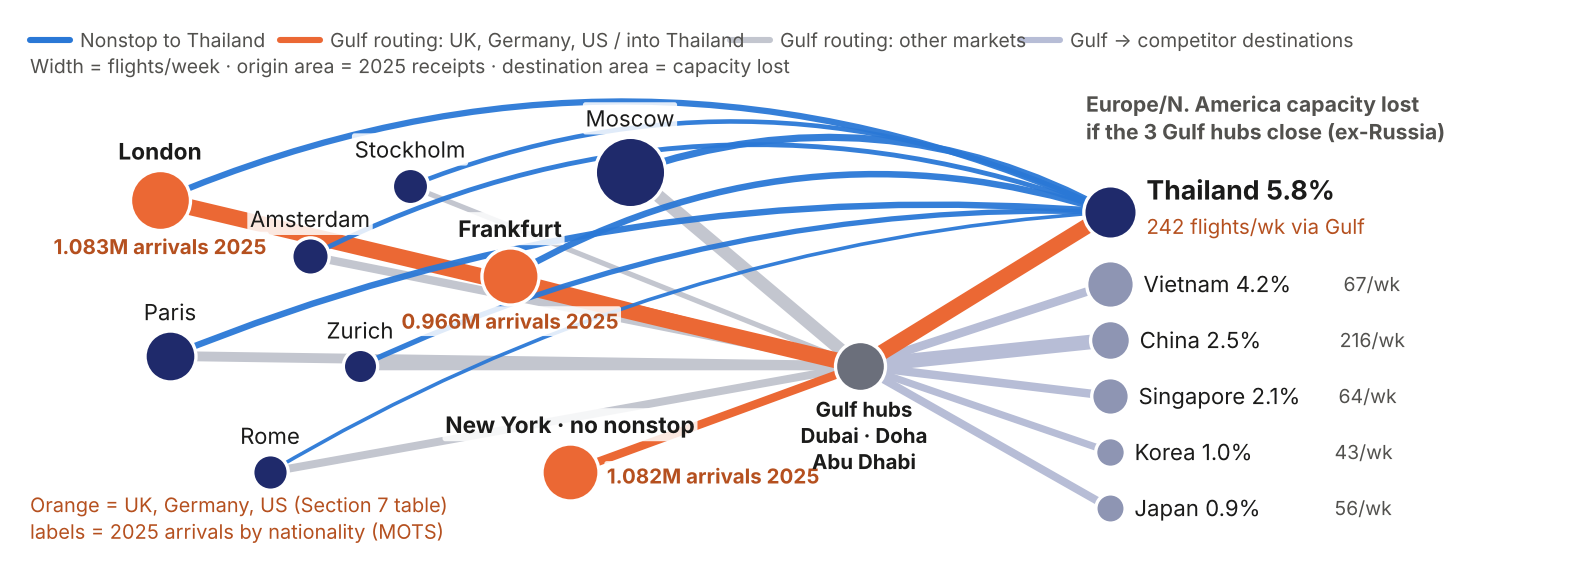

In [17]:
from matplotlib.patches import FancyArrowPatch
INK, INK2 = '#1b1b1a', '#52514e'
ORANGE, GREY_EDGE, HUBC, BLUE = '#eb6834', '#c3c6cf', '#6b6f7b', '#2a78d6'
NAVY, PEER, PEER_EDGE, RUST = '#1F2A6B', '#8e95b3', '#b7bdd6', '#b5501f'

FIG_CITIES = {'London':'United Kingdom','Moscow':'Russia','Frankfurt':'Germany','Paris':'France','New York':'United States',
              'Amsterdam':'Netherlands','Zurich':'Switzerland','Stockholm':'Sweden','Rome':'Italy'}
PRIORITY = {'London', 'Frankfurt', 'New York'}
THAI = [c for c in cc['TH'] if c in ix]
O = {}
for c, mk in FIG_CITIES.items():
    O[c] = dict(rec=V.loc[mk, 'receipts_mb'] / 1000, ns=W[ix[c], [ix[t] for t in THAI]].sum(),
                flows=[W[ix[c], ix[h]] for h in GULF3])
ARR = {c: V.loc[FIG_CITIES[c], 'arr25'] / 1e6 for c in PRIORITY}
DEST = {'Thailand':(G2D['Thailand'], lost3['TH']), 'Vietnam':(G2D['Vietnam'], lost3['VN']), 'China':(G2D['China'], lost3['CN']),
        'Singapore':(G2D['Singapore'], lost3['SG']), 'Korea':(G2D['South Korea'], lost3['KR']), 'Japan':(G2D['Japan'], lost3['JP'])}

Wd, Hd = 7.7, 2.68      # กว้างกว่าฉบับ one-pager เล็กน้อย เพราะฟอนต์เริ่มต้นของ Colab กว้างกว่า
GULF = 'Gulf hubs'
pos = {'London':(0.7,1.78),'Stockholm':(1.95,1.85),'Moscow':(3.05,1.92),'Amsterdam':(1.45,1.5),'Frankfurt':(2.45,1.4),
       'Paris':(0.75,1.0),'Zurich':(1.7,0.95),'Rome':(1.25,0.42),'New York':(2.75,0.42),GULF:(4.2,0.95)}
DX = 5.45
for dname, y in zip(DEST, [1.72, 1.36, 1.08, 0.80, 0.52, 0.24]): pos[dname] = (DX, y)
fig = plt.figure(figsize=(Wd, Hd), dpi=200); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, Wd); ax.set_ylim(0, Hd); ax.axis('off')
r_origin = lambda rec: 2.6 + 0.95 * rec ** 0.5
r_dest   = lambda pct: 2.4 + 3.0 * pct ** 0.5
lw = lambda f: 0.4 + 0.33 * f ** 0.5
def edge(a_, b_, f, color, z, rad=0.0, alpha=1.0):
    ax.add_patch(FancyArrowPatch(pos[a_], pos[b_], connectionstyle=f'arc3,rad={rad}', arrowstyle='-', lw=lw(f), color=color, alpha=alpha, zorder=z, capstyle='round', shrinkA=0, shrinkB=0))
for c, o in O.items():
    g = sum(f for f in o['flows'] if f >= CUT); pr = c in PRIORITY
    edge(c, GULF, g, ORANGE if pr else GREY_EDGE, 2 if pr else 1)
    if o['ns'] >= CUT: edge(c, 'Thailand', o['ns'], BLUE, 3, -0.22 if pos[c][1] >= 1.3 else -0.12, 0.95)
for dname, (gf, pct) in DEST.items(): edge(GULF, dname, gf, ORANGE if dname == 'Thailand' else PEER_EDGE, 3 if dname == 'Thailand' else 2)
BB = dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.85)
node = lambda xy, r, face, z=5: ax.plot(*xy, 'o', ms=2 * r, mfc=face, mec='white', mew=1.2, zorder=z)
for c, o in O.items():
    pr = c in PRIORITY; r_ = r_origin(o['rec']); node(pos[c], r_, ORANGE if pr else NAVY); x_, y_ = pos[c]
    ax.text(x_, y_ + (r_ + 1.8) / 72, c + (' · no nonstop' if pr and o['ns'] < CUT else ''), ha='center', va='bottom', fontsize=8.2 if pr else 8, color=INK, zorder=7, fontweight='bold' if pr else 'normal', bbox=BB)
    if pr:
        if c == 'New York': ax.text(x_ + (r_ + 3) / 72, y_ - 0.02, f'{ARR[c]:.3f}M arrivals 2025', ha='left', va='center', fontsize=7.4, color=RUST, fontweight='bold', zorder=7, bbox=BB)
        else: ax.text(x_, y_ - (r_ + 1.5) / 72, f'{ARR[c]:.3f}M arrivals 2025', ha='center', va='top', fontsize=7.4, color=RUST, fontweight='bold', zorder=7, bbox=BB)
node(pos[GULF], 9, HUBC, 6)
ax.text(pos[GULF][0] + 0.02, pos[GULF][1] - 0.15, 'Gulf hubs\nDubai · Doha\nAbu Dhabi', ha='center', va='top', fontsize=7.4, color=INK, fontweight='bold', linespacing=1.05, zorder=7)
ax.text(DX - 0.12, 2.05, 'Europe/N. America capacity lost\nif the 3 Gulf hubs close (ex-Russia)', ha='left', va='bottom', fontsize=7.6, color=INK2, fontweight='bold', linespacing=1.05)
for dname, (gf, pct) in DEST.items():
    th_ = dname == 'Thailand'; r_ = r_dest(pct); node(pos[dname], r_, NAVY if th_ else PEER, 6); x_, y_ = pos[dname]; tx = x_ + (r_ + 3.5) / 72
    if th_:
        ax.text(tx, y_ + 0.03, f'Thailand {pct:.1f}%', ha='left', va='bottom', fontsize=9.6, color=INK, fontweight='bold')
        ax.text(tx, y_ - 0.01, f'{gf:.0f} flights/wk via Gulf', ha='left', va='top', fontsize=7.4, color=RUST)
    else:
        ax.text(tx, y_, f'{dname} {pct:.1f}%', ha='left', va='center', fontsize=8, color=INK); ax.text(tx + 1.0, y_, f'{gf:.0f}/wk', ha='left', va='center', fontsize=7, color=INK2)
ax.text(0.05, 0.05, 'Orange = UK, Germany, US (Section 7 table)\nlabels = 2025 arrivals by nationality (MOTS)', fontsize=7.2, color=RUST, ha='left', va='bottom', linespacing=1.1)
for lx, (col, t) in zip([0.05, 1.3, 3.55, 5.0], [(BLUE,'Nonstop to Thailand'),(ORANGE,'Gulf routing: UK, Germany, US / into Thailand'),(GREY_EDGE,'Gulf routing: other markets'),(PEER_EDGE,'Gulf → competitor destinations')]):
    ax.plot([lx, lx + 0.2], [2.58, 2.58], color=col, lw=2.2, solid_capstyle='round'); ax.text(lx + 0.25, 2.58, t, fontsize=7, color=INK2, va='center')
ax.text(0.05, 2.45, 'Width = flights/week · origin area = 2025 receipts · destination area = capacity lost', fontsize=7, color=INK2, va='center')
fig.savefig('fig_network.png', dpi=200, facecolor='white'); plt.show()

## Step 14 — สรุปผล + แปลผล (Summary & Interpretation)
เซลล์ถัดไปพิมพ์สรุปโดยดึงตัวเลขจากผลที่เพิ่งคำนวณ (ไม่ได้พิมพ์ตัวเลขเอง) ตามด้วยการตรวจเทียบกับ one-pager

In [18]:
th3 = th.loc[['United Kingdom','Germany','Russia','United States']]
print('='*78); print('สรุปผล (ดึงจากการคำนวณข้างบน)'); print('='*78)
print(f"""
1) กราฟ: {len(ix):,} เมือง, {len(e):,} เส้นทาง (หลัง prune ≥{CUT} เที่ยว/สัปดาห์; ก่อน prune {before[0]:,} เมือง, {before[1]:,} เส้นทาง)
2) Exposure E: UK→Thailand = {x['E']:.3f}  (บินตรง {x['C0']:.1f}/สัปดาห์; ผ่านฮับ Gulf {x['Ch_gcc']:.1f}/สัปดาห์ จากตัวหาร {x['denom']:.1f})
3) E ทำนายการลดลงของนักท่องเที่ยว:  ρ(E, YoY Mar–Apr 2026) = {rho_E:+.2f} (p={p_E:.4f}, n={len(th)})
   - จำนวนเที่ยวบินตรง (nonstop count) ไม่ช่วย: ρ = {rho_C0:+.2f}
   - min-leg E: ρ = {rho_Em:+.2f}  (เครื่องหมายเดิม)
   - Placebo 2025 (ปีที่ไม่มีเหตุการณ์): ρ = {rho_pl:+.2f} (ไม่ติดลบ)
   - Leave-one-hub-out: ρ = {min(v[0] for v in loho.values()):+.2f} ถึง {max(v[0] for v in loho.values()):+.2f}
   - 48 specification: ลบทั้ง {(grid.rho<0).sum()}/{len(grid)}, p<0.05 จำนวน {(grid.p<0.05).sum()}, ρ {grid.rho.min():+.2f} ถึง {grid.rho.max():+.2f}
   - Vietnam (DiD): ρ = {vn.rho_vs_DiD:+.2f} (n={int(vn.n)}) ขณะที่ E vs YoY ดิบ = {vn.rho_vs_YoY:+.2f} (ไม่มีนัย — เพราะเวียดนามโตแรงทุกตลาด จึงต้อง DiD)
4) ปลายทาง: ปิด 3 ฮับ ไทยเสียความจุยุโรป/อเมริกาเหนือ {lost3['TH']:.1f}% (เวียดนาม {lost3['VN']:.1f}%, จีน {lost3['CN']:.1f}%, สิงคโปร์ {lost3['SG']:.1f}%, เกาหลี {lost3['KR']:.1f}%, ญี่ปุ่น {lost3['JP']:.1f}%)
   ฮับ Gulf บินเข้าไทย {G2D['Thailand']:.0f} เที่ยว/สัปดาห์ (จีน {G2D['China']:.0f})
5) ตลาดหลัก: UK E={th3.loc['United Kingdom','E']:.3f} YoY {th3.loc['United Kingdom','yoy_MarApr26_pct']:+.1f}% | Germany E={th3.loc['Germany','E']:.3f} YoY {th3.loc['Germany','yoy_MarApr26_pct']:+.1f}%
   Russia (บินตรงมากสุด) E={th3.loc['Russia','E']:.3f} YoY {th3.loc['Russia','yoy_MarApr26_pct']:+.1f}% | US E={th3.loc['United States','E']:.3f} YoY {th3.loc['United States','yoy_MarApr26_pct']:+.1f}%
6) Exposed (E × รายรับ 2025, เพดานแบบไม่เปลี่ยนเส้นทาง): UK {M7.loc['United Kingdom','exposed_bn']:.1f} bn, Germany {M7.loc['Germany','exposed_bn']:.1f} bn, US {M7.loc['United States','exposed_bn']:.1f} bn
7) Trigger (Europe→Gulf3 ต่ำกว่าปีก่อน ≥10% สองสัปดาห์): ยิงวันที่ {first26.date()} ในข้อมูลจริง; ตารางบิน 2 ต.ค. เข้าเงื่อนไขวันที่ {firstS.date()}
""")

สรุปผล (ดึงจากการคำนวณข้างบน)

1) กราฟ: 978 เมือง, 15,533 เส้นทาง (หลัง prune ≥3 เที่ยว/สัปดาห์; ก่อน prune 1,196 เมือง, 22,401 เส้นทาง)
2) Exposure E: UK→Thailand = 0.083  (บินตรง 31.6/สัปดาห์; ผ่านฮับ Gulf 8.9/สัปดาห์ จากตัวหาร 106.1)
3) E ทำนายการลดลงของนักท่องเที่ยว:  ρ(E, YoY Mar–Apr 2026) = -0.70 (p=0.0005, n=20)
   - จำนวนเที่ยวบินตรง (nonstop count) ไม่ช่วย: ρ = +0.24
   - min-leg E: ρ = -0.57  (เครื่องหมายเดิม)
   - Placebo 2025 (ปีที่ไม่มีเหตุการณ์): ρ = +0.32 (ไม่ติดลบ)
   - Leave-one-hub-out: ρ = -0.74 ถึง -0.62
   - 48 specification: ลบทั้ง 48/48, p<0.05 จำนวน 40, ρ -0.79 ถึง -0.42
   - Vietnam (DiD): ρ = -0.76 (n=16) ขณะที่ E vs YoY ดิบ = -0.25 (ไม่มีนัย — เพราะเวียดนามโตแรงทุกตลาด จึงต้อง DiD)
4) ปลายทาง: ปิด 3 ฮับ ไทยเสียความจุยุโรป/อเมริกาเหนือ 5.8% (เวียดนาม 4.2%, จีน 2.5%, สิงคโปร์ 2.1%, เกาหลี 1.0%, ญี่ปุ่น 0.9%)
   ฮับ Gulf บินเข้าไทย 242 เที่ยว/สัปดาห์ (จีน 216)
5) ตลาดหลัก: UK E=0.083 YoY -9.5% | Germany E=0.048 YoY -13.7%
   Russia (บินตรงมากสุด) E=0.033 YoY -8.

### แปลผล (Interpretation)
1. **กราฟบอกอะไรที่ตารางนับเที่ยวบินตรงบอกไม่ได้** — ตลาดที่มีเที่ยวบินตรงมากสุด (รัสเซีย) ไม่ใช่ตลาดที่พึ่งพิง Gulf มากที่สุด ρ ของ nonstop count เป็นบวก (+0.24 ไม่มีนัย) ขณะที่ E ได้ ρ ≈ −0.70: **ยิ่งต้องเปลี่ยนเครื่องที่ฮับ Gulf มาก ยิ่งลดลงมาก**
2. **ผลไม่ได้มาจากการเลือกพารามิเตอร์** — เครื่องหมายติดลบใน 48/48 specification, ไม่ขึ้นกับฮับใดฮับหนึ่ง (leave-one-hub-out), และ placebo ปี 2025 ที่ไม่มีเหตุการณ์ไม่ให้ความสัมพันธ์ติดลบ
3. **ไทยเปราะบางกว่าคู่แข่งส่วนใหญ่** — ปิด 3 ฮับ ไทยสูญเสียความจุจากยุโรป/อเมริกาเหนือ 5.8% สูงสุดใน 6 ปลายทาง และ Gulf เป็นผู้ให้บริการเที่ยวบินเข้าไทยถึง 242 เที่ยว/สัปดาห์ ใกล้เคียงกับจีนที่ตลาดบินตรงใหญ่กว่ามาก (จึงพึ่งพิงน้อยกว่า)
4. **ข้อควรระวังในการตีความ**
   - E เป็น *routing proxy* จากตารางบิน (planned flights) ไม่ใช่พฤติกรรมของนักท่องเที่ยว — UK CAA ชี้ว่าผู้โดยสารหายไป 59% ขณะตารางบินลดแค่ 1% เพราะฉะนั้นตารางบินวัด "ความพึ่งพิง" ไม่ใช่ "ความเสียหาย"
   - ความสัมพันธ์ระดับตลาด n = 20 เป็นหลักฐานเชิงสหสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ (ผ่าน placebo, DiD และ 48 specification เพื่อลดความเป็นไปได้ของคำอธิบายอื่น)
   - **Exposed** (E × รายรับ 2025) เป็นเพดานแบบไม่มีการเปลี่ยนเส้นทาง ไม่ใช่การพยากรณ์ความเสียหาย
   - ถ้าข้อมูลการจองแสดงว่านักท่องเที่ยว UK/เยอรมันเปลี่ยนไปใช้ Istanbul หรือบินตรง → ไม่ต้องย้ายงบ (Section 8: What would change my mind)
5. **การตัดสินใจ:** แบ่งงบที่ปล่อยได้ให้ UK ~2/3 และ Germany ~1/3 ตาม Exposed; US ถือไว้ (ลดแค่ −1.1%) เพิ่มเข้าเมื่อลดถึง 5%; รัสเซียไม่ย้ายงบ (E ต่ำกว่า median); ตลาดที่ผ่านเกณฑ์ลำดับถัดไปแต่ Exposed < 3 bn (Poland 1.6, Italy 1.1, Spain 1.0 …) อยู่ในชีต `section7_exposed_table` ไม่ได้แสดงบนหน้าเดียวเพราะพื้นที่จำกัด; ปล่อยงบ Tier 1 ภายใน 30 ต.ค. หลังตรวจข้อมูลการจอง เพราะตารางบิน 2 ต.ค. เข้าเงื่อนไข trigger วันที่ 20 ต.ค.

In [19]:
# ---- ตรวจตัวเลขที่คำนวณได้ เทียบกับตัวเลขที่พิมพ์ใน one-pager ----
rows = []
for name, got, exp, tol in CHECKS:
    ok = (got == exp) if isinstance(exp, str) else abs(float(got) - float(exp)) <= tol + 1e-9
    rows.append(dict(item=name, computed=got if isinstance(got, str) else round(float(got), 4), onepager=exp, ok='✔' if ok else '✘'))
CK = pd.DataFrame(rows); RESULTS['check_vs_onepager'] = CK
print(CK.to_string(index=False))
print(f"\nตรงกัน {(CK.ok == '✔').sum()}/{len(CK)} รายการ")

                               item               computed               onepager ok
                   nodes หลัง prune                  978.0                    978  ✔
                   edges หลัง prune                15533.0                  15533  ✔
                   nodes ก่อน prune                 1196.0                   1196  ✔
                   edges ก่อน prune                22401.0                  22401  ✔
                           C0 UK→TH                31.5714                  31.57  ✔
                       Ch_gcc UK→TH                 8.8531                   8.85  ✔
                       ตัวหาร UK→TH               106.0626                 106.06  ✔
                            E UK→TH                 0.0835                  0.083  ✔
                  E เฉลี่ย Thailand                 0.0599                   0.06  ✔
                   E เฉลี่ย Vietnam                 0.0575                  0.058  ✔
                                ρ E                -0.7038       

## Step 15 — บันทึกผลเป็น Excel
เขียนตารางผลลัพธ์ทั้งหมดลงไฟล์ `MADT7202_Midterm_results.xlsx` (มีชีต README อธิบายทุกชีต) แล้วดาวน์โหลด

In [20]:
DESC = {'edges_preclosure_all':'เส้นทางบินตรงทุกคู่เมืองก่อน prune ช่วง 6 ม.ค.–17 ก.พ. 2026 (เที่ยว/สัปดาห์) + flag ว่าผ่านเกณฑ์ ≥3 หรือไม่',
 'E_20_markets_x_6_dest':'Exposure E (proportional และ min-leg) และ C0 ของ 20 ตลาด × 6 ปลายทาง',
 'TH_validation_20_markets':'20 ตลาด → Thailand: E, YoY Mar–Apr 2026 และอันดับ (ใช้คำนวณ Spearman ρ)',
 'E_TH_2025_vs_2026':'E ปี 2025 vs 2026 และ YoY ปี 2025 (placebo) / ปี 2026 สำหรับไทย',
 'robustness_48_specs':'Spearman ρ 48 specifications (หน้าต่าง × cutoff × ชุดฮับ × ตัวแปรผลลัพธ์)',
 'VN_JP_TH_DiD':'Vietnam / Thailand / Japan: ρ ระหว่าง E กับ YoY และ DiD',
 'capacity_lost_if_hubs_close':'ความจุที่หายถ้าปิด 3 ฮับ (และ GCC-10) ต่อปลายทาง + เที่ยวบินตรงยุโรป/สหรัฐ',
 'gulf3_to_destination':'เที่ยวบินจาก Dubai+Doha+Abu Dhabi ไปแต่ละปลายทาง (เที่ยว/สัปดาห์)',
 'trigger_weekly_2026':'Trigger: เที่ยวบิน Europe→Gulf3 รายสัปดาห์ 2026 เทียบปีก่อน',
 'trigger_schedule_asof_20261002':'Trigger: ตารางบินล่วงหน้า as of 2 ต.ค. 2026 เทียบปีก่อน',
 'UK_CAA_passengers_yoy':'UK CAA: ผู้โดยสาร UK↔ปลายทาง % YoY รายเดือน',
 'section7_exposed_table':'ตลาด 20 ตลาด: E, YoY, รายรับ, บาท/ทริป, Exposed (bn)',
 'section7_focus_markets':'ตลาดที่แสดงในตาราง Section 7 ของ one-pager',
 'check_vs_onepager':'ผลตรวจตัวเลขที่คำนวณ vs ตัวเลขใน one-pager'}
README = pd.DataFrame({'sheet': ['README'] + list(RESULTS), 'content': ['สร้างโดย MADT7202_Midterm_Notebook.ipynb — ตัวเลขทุกตารางตรงกับ one-pager (ดูชีต check_vs_onepager)'] + [DESC.get(k, '') for k in RESULTS]})
OUTX = 'MADT7202_Midterm_results.xlsx'
with pd.ExcelWriter(OUTX, engine='openpyxl') as xw:
    README.to_excel(xw, sheet_name='README', index=False)
    for k, df in RESULTS.items(): df.to_excel(xw, sheet_name=k[:31], index=False)
    for ws in xw.book.worksheets:
        ws.freeze_panes = 'A2'
        from openpyxl.styles import Font, PatternFill
        for c in ws[1]: c.font = Font(bold=True, color='FFFFFF'); c.fill = PatternFill('solid', fgColor='1F2A6B')
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(48, max(10, max(len(str(c.value)) if c.value is not None else 0 for c in col[:60]) + 2))
print('บันทึกแล้ว:', OUTX, '| จำนวนชีต', len(RESULTS) + 1)
if IN_COLAB:
    files.download(OUTX); files.download('fig_network.png')

บันทึกแล้ว: MADT7202_Midterm_results.xlsx | จำนวนชีต 15
